# Calor, frio e óbitos de idosos em São Paulo — Random Forest

**Pergunta:** dado o clima externo dos últimos dias, quantos óbitos de pessoas com 60+ anos são esperados hoje na cidade de São Paulo, em relação ao normal?

**Para que serve no produto (Termômetro do ACS):** o modelo encontra as temperaturas **externas** a partir das quais a mortalidade de idosos sobe, no **calor** e no **frio**. Esses limiares viram o "dia de risco" da API: nesses dias, o semáforo de cada casa sobe um degrau.

**Dados (reais e públicos):** INMET, estação A701 (Mirante de Santana), e SIM/DATASUS (declarações de óbito), 2014–2023. Veja `dados/README.md`.

**O modelo NÃO mede a casa nem prevê a morte de uma pessoa.** Ele descreve a cidade inteira, dia a dia. A casa é medida pelo sensor.

In [1]:
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

SEED = 42
ANO_TESTE = 2023            # o ano mais recente fica de fora: simula "prever o futuro"
ANOS_COVID = [2020, 2021]   # fora do treino (excesso de mortes da pandemia)
LIMITE_EXCESSO_2022 = 0.10  # meses de 2022 com >10% de excesso também saem
RR_CORTE = 1.05             # "dia de risco": 5% mais óbitos que o esperado
MIN_DIAS_FAIXA = 15         # faixa de temperatura com menos dias que isso não é confiável

PROC = Path("dados/processados")
RES = Path("resultados")
RES.mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Dados

In [2]:
clima = pd.read_csv(PROC / "clima_a701_diario.csv", parse_dates=["data"]).set_index("data")
obitos = pd.read_csv(PROC / "obitos60_capital_diario.csv", parse_dates=["data"]).set_index("data")

# Calendário completo: os lags precisam de dias consecutivos, mesmo os que depois saem do treino
dias = pd.date_range("2014-01-01", "2023-12-31", freq="D")
df = clima.reindex(dias).join(obitos.reindex(dias))
df.index.name = "data"
print(df.shape)
print("Dias sem óbitos registrados:", int(df["obitos_60mais"].isna().sum()))
print("Dias sem máxima válida:", int(df["tmax"].isna().sum()))
df.describe().round(1).T

(3652, 10)
Dias sem óbitos registrados: 0
Dias sem máxima válida: 29


,count,mean,std,min,25%,50%,75%,max
tmax,3623.0,26.6,4.5,12.0,23.5,27.0,29.9,38.4
tmin,3623.0,16.8,3.1,4.0,14.7,17.1,19.2,25.2
tmed,3623.0,20.6,3.4,8.2,18.4,20.8,23.1,31.0
umid_med,3623.0,68.4,10.4,27.7,62.9,69.6,75.4,93.3
umid_min,3623.0,45.0,15.3,12.0,33.0,44.0,55.0,90.0
orvalho_med,3623.0,13.9,3.3,-0.3,11.5,14.4,16.7,20.2
chuva_mm,3625.0,4.2,10.6,0.0,0.0,0.0,2.4,142.4
horas_validas,3652.0,23.8,1.6,0.0,24.0,24.0,24.0,24.0
obitos_60mais,3652.0,163.1,32.5,73.0,142.0,157.0,177.0,403.0
obitos_60mais_circ_resp,3652.0,77.5,13.7,37.0,68.0,76.5,85.0,148.0


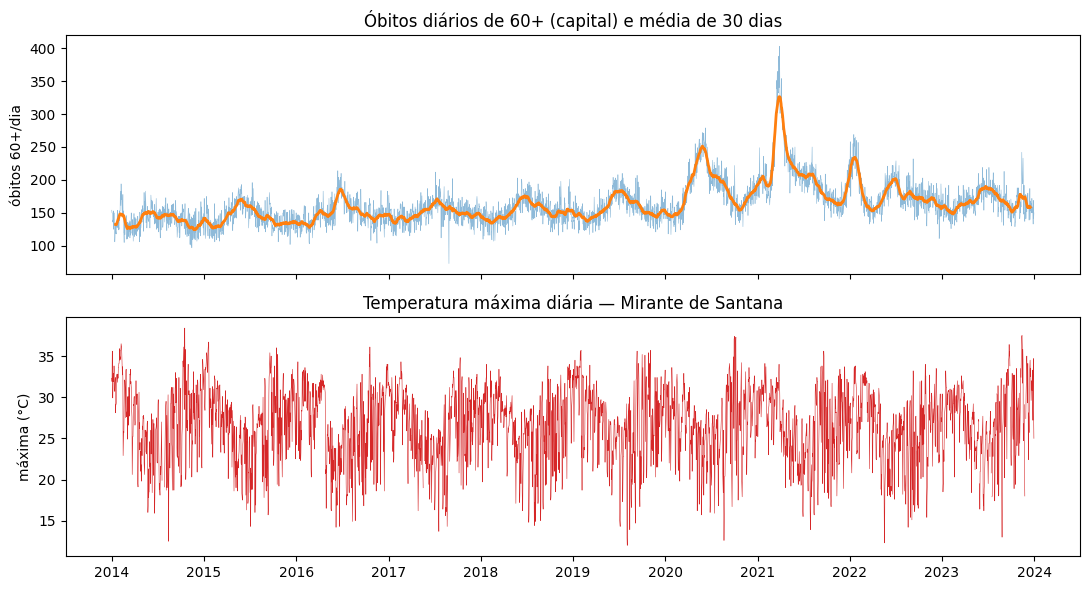

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(df.index, df["obitos_60mais"], lw=0.4, alpha=0.5)
ax[0].plot(df.index, df["obitos_60mais"].rolling(30, center=True).mean(), lw=2)
ax[0].set_ylabel("óbitos 60+/dia")
ax[0].set_title("Óbitos diários de 60+ (capital) e média de 30 dias")
ax[1].plot(df.index, df["tmax"], lw=0.4, color="tab:red")
ax[1].set_ylabel("máxima (°C)")
ax[1].set_title("Temperatura máxima diária — Mirante de Santana")
plt.tight_layout(); plt.savefig(RES / "01_series.png", dpi=120); plt.show()

## 2. COVID: quais meses saem do treino

A pandemia (2020–2021) criou um excesso de mortes que não tem relação com o clima. Se esses dias ficassem no treino, o modelo aprenderia "pandemia" no lugar de "temperatura".
Para 2022, deixamos o **dado decidir**: comparamos cada mês com o esperado (média de 2014–2019 para aquele mês, corrigida pela tendência de alta de óbitos com o envelhecimento da população) e retiramos os meses com mais de 10% de excesso.

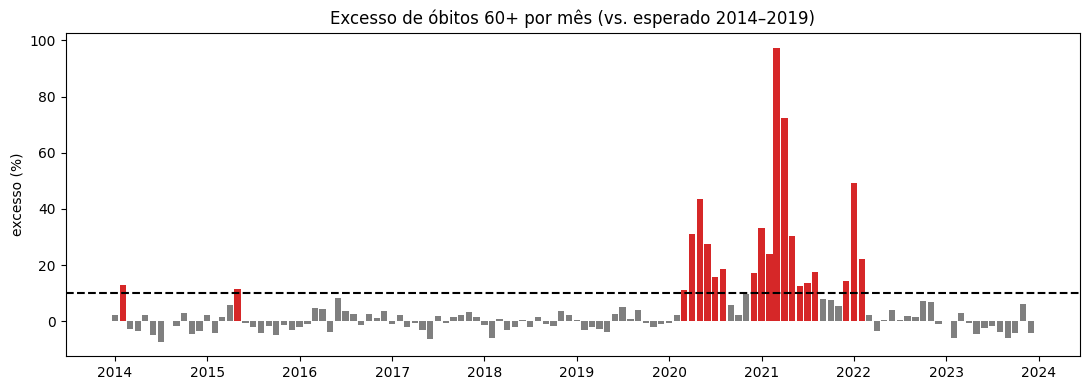

Meses de 2022 retirados: ['01/2022', '02/2022']


,obitos,esperado,excesso
data,,,
2020-01-01,4596,4618.45,-0.00
2020-02-01,4278,4189.43,0.02
2020-03-01,5139,4626.00,0.11
2020-04-01,6155,4691.09,0.31
2020-05-01,7473,5210.36,0.43
2020-06-01,6915,5420.73,0.28
2020-07-01,6352,5492.12,0.16
2020-08-01,6158,5198.14,0.18
2020-09-01,5157,4876.29,0.06


In [4]:
mensal = df["obitos_60mais"].resample("MS").sum().to_frame("obitos")
mensal["ano"] = mensal.index.year
mensal["mes"] = mensal.index.month

base = mensal[mensal["ano"] <= 2019]
anual = base.groupby("ano")["obitos"].sum()
tend = LinearRegression().fit(anual.index.values.reshape(-1, 1), anual.values)
peso_mes = base.groupby("mes")["obitos"].sum() / base["obitos"].sum()   # sazonalidade típica

mensal["esperado"] = tend.predict(mensal[["ano"]].values) * mensal["mes"].map(peso_mes)
mensal["excesso"] = mensal["obitos"] / mensal["esperado"] - 1

fig, ax = plt.subplots()
ax.bar(mensal.index, mensal["excesso"] * 100, width=25,
       color=np.where(mensal["excesso"] > LIMITE_EXCESSO_2022, "tab:red", "tab:gray"))
ax.axhline(LIMITE_EXCESSO_2022 * 100, ls="--", color="k")
ax.set_ylabel("excesso (%)"); ax.set_title("Excesso de óbitos 60+ por mês (vs. esperado 2014–2019)")
plt.tight_layout(); plt.savefig(RES / "02_excesso_covid.png", dpi=120); plt.show()

meses_2022_fora = mensal[(mensal["ano"] == 2022) & (mensal["excesso"] > LIMITE_EXCESSO_2022)].index
print("Meses de 2022 retirados:", [m.strftime("%m/%Y") for m in meses_2022_fora])
mensal.loc["2020":"2022", ["obitos", "esperado", "excesso"]].round(2)

## 3. De "número de óbitos" para "risco relativo"

A população de SP envelhece, então o número de óbitos de 60+ sobe todo ano. Modelos de árvore (como a Random Forest) não conseguem **extrapolar** uma tendência: prevendo 2023, ficariam presos no nível dos anos de treino.
Solução: ajustamos a tendência anual **só com os anos de treino** e o alvo do modelo vira o **risco relativo (RR)** = óbitos do dia ÷ óbitos esperados para aquele ano. RR = 1,10 significa "10% acima do normal".

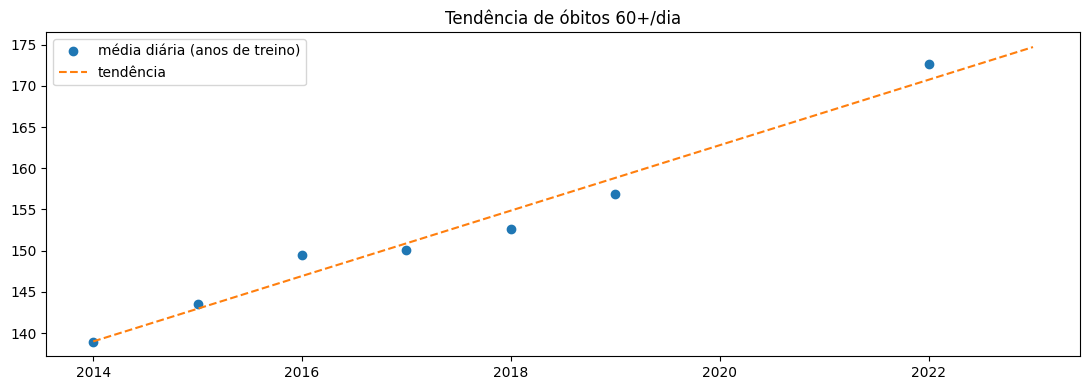

Inclinação: +4.0 óbitos/dia por ano


In [5]:
df["ano"] = df.index.year
mes_inicio = df.index.to_period("M").to_timestamp()
fora = df["ano"].isin(ANOS_COVID) | mes_inicio.isin(meses_2022_fora)
treino_mask = (~fora) & (df["ano"] != ANO_TESTE) & df["obitos_60mais"].notna()
teste_mask = (df["ano"] == ANO_TESTE) & df["obitos_60mais"].notna()

media_ano = df[treino_mask].groupby("ano")["obitos_60mais"].mean()
tend_dia = LinearRegression().fit(media_ano.index.values.reshape(-1, 1), media_ano.values)
df["esperado"] = tend_dia.predict(df[["ano"]].values)
df["rr"] = df["obitos_60mais"] / df["esperado"]

anos = np.arange(2014, 2024)
plt.plot(media_ano.index, media_ano.values, "o", label="média diária (anos de treino)")
plt.plot(anos, tend_dia.predict(anos.reshape(-1, 1)), "--", label="tendência")
plt.title("Tendência de óbitos 60+/dia"); plt.legend()
plt.tight_layout(); plt.savefig(RES / "03_tendencia.png", dpi=120); plt.show()
print("Inclinação: %+.1f óbitos/dia por ano" % tend_dia.coef_[0])

## 4. Variáveis do modelo

O efeito do clima não é só no mesmo dia: o calor costuma agir em 0–3 dias e o frio demora mais. Por isso usamos **lags de 0 a 7 dias** das temperaturas, médias móveis, umidade e o dia da semana.
Não usamos "mês" nem "dia do ano" de propósito: queremos que o modelo explique os óbitos pelo **clima**, e não pela data no calendário (veja as limitações no fim).

In [6]:
X = pd.DataFrame(index=df.index)
for lag in range(0, 8):
    for v in ["tmax", "tmin", "tmed"]:
        X[f"{v}_lag{lag}"] = df[v].shift(lag)
X["tmed_media_0a3"] = df["tmed"].rolling(4, min_periods=3).mean()
X["tmed_media_0a7"] = df["tmed"].rolling(8, min_periods=6).mean()
X["amplitude_lag0"] = df["tmax"] - df["tmin"]
X["umid_med_lag0"] = df["umid_med"]
X["umid_min_lag0"] = df["umid_min"]
X["orvalho_lag0"] = df["orvalho_med"]
X["chuva_lag0"] = df["chuva_mm"]
X["dia_semana"] = df.index.dayofweek
y = df["rr"]
print(X.shape[1], "variáveis")

32 variáveis


## 5. Divisão treino / teste

- **Treino:** 2014–2019 + meses válidos de 2022.
- **Teste:** 2023 inteiro (o modelo nunca viu esse ano).
- Sem embaralhar: em série temporal, embaralhar deixaria o modelo "espiar" o futuro.
- A validação cruzada (`TimeSeriesSplit`) roda **só dentro do treino**: cada dobra treina no passado e valida no período seguinte.

Dias sem temperatura (poucos) saem do treino e do teste, porque o modelo precisa de todas as variáveis preenchidas.

In [7]:
completo = X.notna().all(axis=1)
treino_mask &= completo
teste_mask &= completo
X_tr, y_tr = X[treino_mask], y[treino_mask]
X_te, y_te = X[teste_mask], y[teste_mask]
print(f"Treino: {len(X_tr)} dias ({X_tr.index.min().date()} a {X_tr.index.max().date()})")
print(f"Teste:  {len(X_te)} dias ({X_te.index.min().date()} a {X_te.index.max().date()})")

Treino: 2453 dias (2014-01-08 a 2022-12-31)
Teste:  285 dias (2023-01-01 a 2023-12-31)


## 6. Modelo: Random Forest e busca de hiperparâmetros

**Por que Random Forest:** a relação entre temperatura e mortalidade tem forma de **"U"** (sobe no frio e no calor), com efeitos atrasados e interações (calor + umidade). Uma reta (regressão linear) não desenha um "U". A Random Forest junta muitas árvores de decisão, cada uma treinada numa amostra diferente dos dados, e tira a média: captura curvas e interações sem precisarmos escrever a fórmula, e a média de várias árvores reduz o overfitting de uma árvore sozinha.

Mesmo padrão da aula de 19/08 (`GridSearchCV` com uma grade de hiperparâmetros), com uma diferença importante: em vez de `StratifiedKFold(shuffle=True)`, usamos **`TimeSeriesSplit`**. Embaralhar dias deixaria o modelo treinar com o futuro e validar no passado ("espiar a prova").

**Hiperparâmetros testados (24 combinações de 3 parâmetros):**
- `max_depth`: profundidade de cada árvore (mais fundo = mais detalhe = mais risco de decorar; `None` = cresce até o fim);
- `n_estimators`: quantas árvores;
- `max_features`: fração das variáveis que cada divisão pode olhar (menos = árvores mais diferentes entre si).

In [8]:
grade = {
    "max_depth": [3, 5, 8, None],
    "n_estimators": [100, 300],
    "max_features": [0.3, 0.6, 1.0],
}
base_modelo = RandomForestRegressor(random_state=SEED, n_jobs=-1)
busca = GridSearchCV(base_modelo, grade, cv=TimeSeriesSplit(n_splits=5),
                     scoring="neg_mean_absolute_error", return_train_score=True, n_jobs=1)
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    "max_depth": res["param_max_depth"].astype(str), "n_estimators": res["param_n_estimators"],
    "max_features": res["param_max_features"],
    "MAE_treino": -res["mean_train_score"], "MAE_validacao": -res["mean_test_score"],
})
tabela["diferenca"] = tabela["MAE_validacao"] - tabela["MAE_treino"]
tabela = tabela.sort_values("MAE_validacao").reset_index(drop=True)
tabela.to_csv(RES / "busca_hiperparametros.csv", index=False)
print("Melhor:", busca.best_params_)
tabela.round(4)

Melhor: {'max_depth': 5, 'max_features': 0.3, 'n_estimators': 300}


,max_depth,n_estimators,max_features,MAE_treino,MAE_validacao,diferenca
0,5,300,0.3,0.0714,0.0824,0.0110
1,8,300,0.3,0.0571,0.0827,0.0256
2,5,100,0.3,0.0714,0.0828,0.0114
3,5,300,0.6,0.0705,0.0830,0.0125
4,8,300,0.6,0.0559,0.0830,0.0271
5,3,300,0.3,0.0789,0.0830,0.0041
6,None,300,0.3,0.0302,0.0830,0.0528
7,8,100,0.3,0.0571,0.0831,0.0260
8,3,100,0.3,0.0789,0.0833,0.0044
9,5,100,0.6,0.0705,0.0833,0.0128


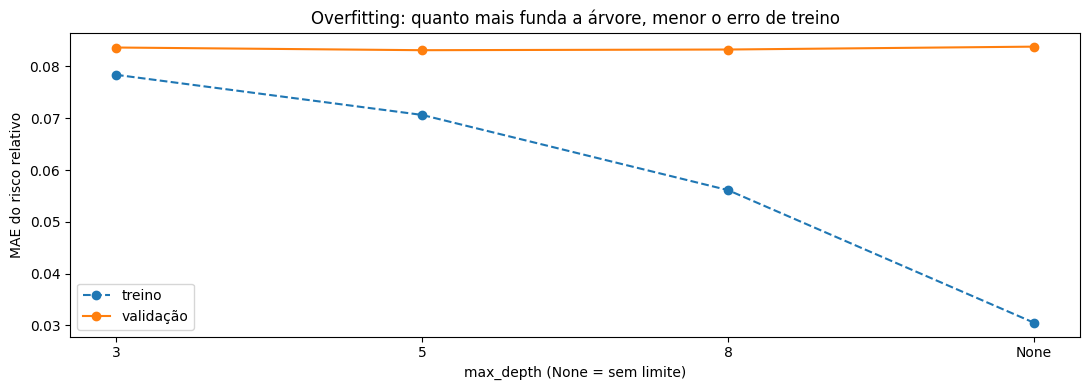

In [9]:
ordem = ["3", "5", "8", "None"]
g = tabela.groupby("max_depth")[["MAE_treino", "MAE_validacao"]].mean().reindex(ordem)
fig, ax = plt.subplots()
ax.plot(g.index, g["MAE_treino"], "o--", label="treino")
ax.plot(g.index, g["MAE_validacao"], "o-", label="validação")
ax.set_xlabel("max_depth (None = sem limite)"); ax.set_ylabel("MAE do risco relativo")
ax.set_title("Overfitting: quanto mais funda a árvore, menor o erro de treino")
ax.legend(); plt.tight_layout(); plt.savefig(RES / "04_overfitting.png", dpi=120); plt.show()

**Como ler:** quando a linha de treino desce e a de validação fica parada ou sobe, o modelo está **decorando** o treino (overfitting), como um aluno que decora as respostas da lista e erra a prova. Escolhemos a combinação com o **menor erro de validação**, não de treino.

## 7. Resultados: treino x teste

In [10]:
modelo = busca.best_estimator_

def metricas(y_real, y_prev, esperado):
    ob_real, ob_prev = y_real * esperado, y_prev * esperado
    return {
        "MAE (RR)": mean_absolute_error(y_real, y_prev),
        "RMSE (RR)": np.sqrt(mean_squared_error(y_real, y_prev)),
        "R²": r2_score(y_real, y_prev),
        "MAE (óbitos/dia)": mean_absolute_error(ob_real, ob_prev),
    }

p_tr, p_te = modelo.predict(X_tr), modelo.predict(X_te)
esp_tr, esp_te = df.loc[treino_mask, "esperado"], df.loc[teste_mask, "esperado"]
comparacao = pd.DataFrame({
    "Treino (Random Forest)": metricas(y_tr, p_tr, esp_tr),
    "Teste 2023 (Random Forest)": metricas(y_te, p_te, esp_te),
    "Teste 2023 (referência: só tendência, RR=1)": metricas(y_te, np.ones(len(y_te)), esp_te),
}).round(3)
comparacao.to_csv(RES / "metricas_treino_teste.csv")
comparacao

,Treino (Random Forest),Teste 2023 (Random Forest),"Teste 2023 (referência: só tendência, RR=1)"
MAE (RR),0.075,0.074,0.099
RMSE (RR),0.094,0.092,0.119
R²,0.403,0.289,-0.187
MAE (óbitos/dia),11.285,12.948,17.375


A **referência** prevê sempre RR = 1 ("hoje é um dia normal"). Se a Random Forest não for melhor que ela no teste, o clima não está ajudando a explicar os óbitos. A diferença entre as colunas de treino e de teste mostra o tamanho do overfitting que sobrou.

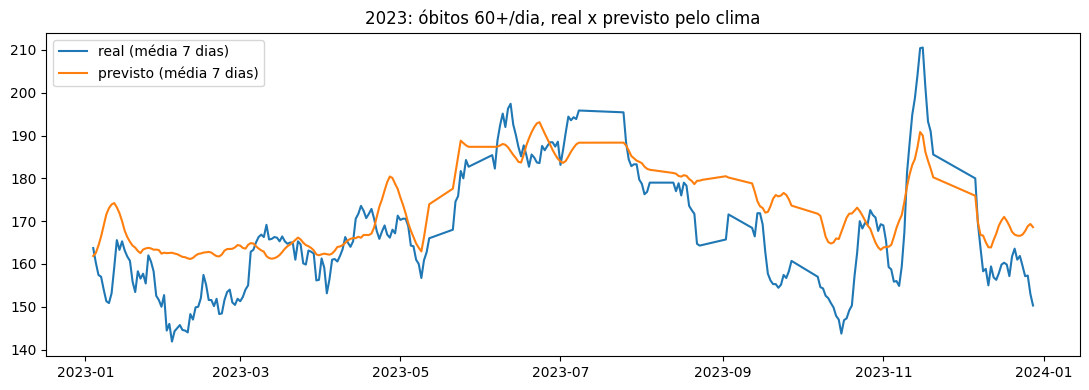

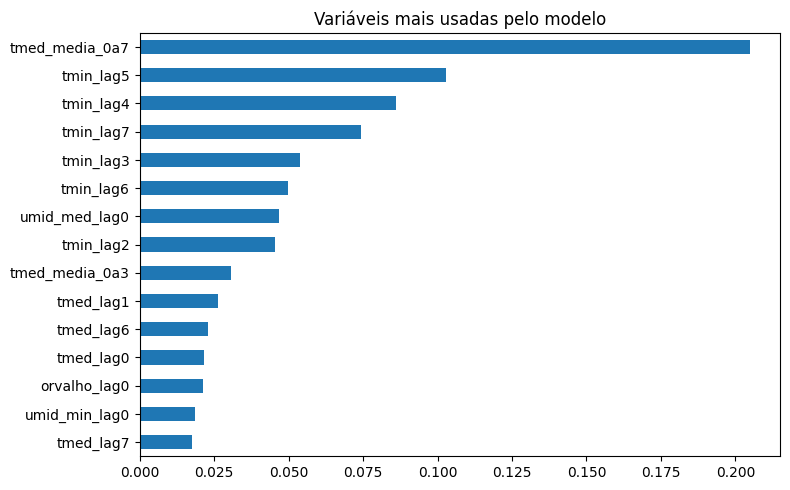

In [11]:
real = df.loc[teste_mask, "obitos_60mais"]
prev = p_te * esp_te
fig, ax = plt.subplots()
ax.plot(real.index, real.rolling(7, center=True).mean(), label="real (média 7 dias)")
ax.plot(real.index, pd.Series(prev, index=real.index).rolling(7, center=True).mean(),
        label="previsto (média 7 dias)")
ax.set_title(f"{ANO_TESTE}: óbitos 60+/dia, real x previsto pelo clima"); ax.legend()
plt.tight_layout(); plt.savefig(RES / "05_teste_real_previsto.png", dpi=120); plt.show()

imp = pd.Series(modelo.feature_importances_, index=X.columns).sort_values().tail(15)
imp.plot.barh(figsize=(8, 5), title="Variáveis mais usadas pelo modelo")
plt.tight_layout(); plt.savefig(RES / "06_importancia.png", dpi=120); plt.show()

## 8. Curva de risco e limiares para o produto

Para cada faixa de 1 °C de temperatura **externa do dia**, calculamos o risco relativo médio **previsto pelo modelo** (e o observado, para comparar). Usamos dias reais (treino + teste), então só aparecem combinações de clima que de fato acontecem em SP.

- **Temperatura de menor risco:** a faixa com o menor RR previsto.
- **Limiar de calor:** a primeira máxima acima dela em que o RR previsto passa de `RR_CORTE` (5% acima do normal).
- **Limiar de frio:** a mínima mais alta, abaixo da de menor risco, em que o RR passa de `RR_CORTE`.

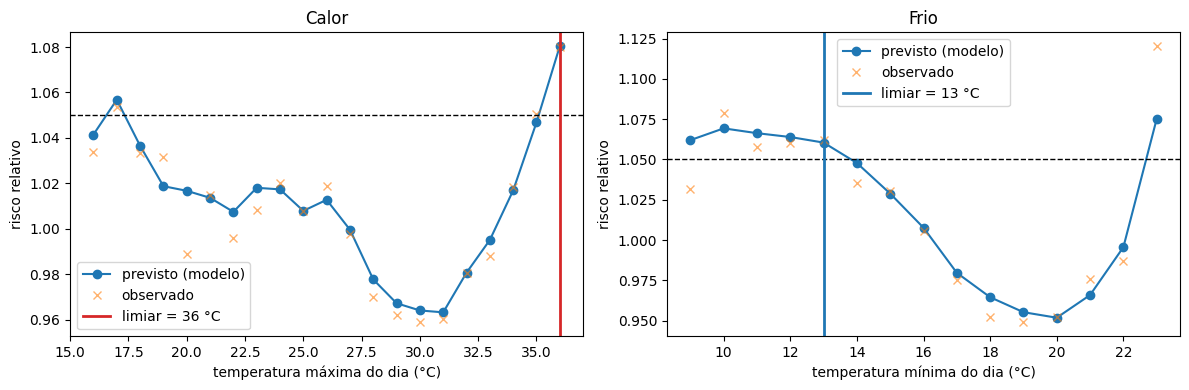

Máxima de menor risco: 31 °C
Limiar de calor (máxima): 36.0
Limiar de frio (mínima): 13.0


In [12]:
uso = treino_mask | teste_mask
curva_base = pd.DataFrame({"rr_prev": modelo.predict(X[uso]), "rr_obs": y[uso],
                           "tmax": df.loc[uso, "tmax"], "tmin": df.loc[uso, "tmin"]})

def curva(col):
    faixa = curva_base[col].round()
    c = curva_base.groupby(faixa).agg(rr_prev=("rr_prev", "mean"), rr_obs=("rr_obs", "mean"),
                                      dias=("rr_prev", "size"))
    return c[c["dias"] >= MIN_DIAS_FAIXA]

c_max, c_min = curva("tmax"), curva("tmin")
t_menor_risco = float(c_max["rr_prev"].idxmin())
acima = c_max[(c_max.index > t_menor_risco) & (c_max["rr_prev"] >= RR_CORTE)]
limiar_calor = float(acima.index.min()) if len(acima) else None

t_menor_risco_min = float(c_min["rr_prev"].idxmin())
abaixo = c_min[(c_min.index < t_menor_risco_min) & (c_min["rr_prev"] >= RR_CORTE)]
limiar_frio = float(abaixo.index.max()) if len(abaixo) else None

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, c, nome, lim, cor in [(ax[0], c_max, "máxima", limiar_calor, "tab:red"),
                             (ax[1], c_min, "mínima", limiar_frio, "tab:blue")]:
    a.plot(c.index, c["rr_prev"], "o-", label="previsto (modelo)")
    a.plot(c.index, c["rr_obs"], "x", alpha=0.6, label="observado")
    a.axhline(RR_CORTE, ls="--", color="k", lw=1)
    if lim is not None:
        a.axvline(lim, color=cor, lw=2, label=f"limiar = {lim:.0f} °C")
    a.set_xlabel(f"temperatura {nome} do dia (°C)"); a.set_ylabel("risco relativo"); a.legend()
ax[0].set_title("Calor"); ax[1].set_title("Frio")
plt.tight_layout(); plt.savefig(RES / "07_curva_risco.png", dpi=120); plt.show()

print("Máxima de menor risco: %.0f °C" % t_menor_risco)
print("Limiar de calor (máxima):", limiar_calor if limiar_calor else "não encontrado com dias suficientes")
print("Limiar de frio (mínima):", limiar_frio if limiar_frio else "não encontrado com dias suficientes")

In [13]:
saida = {
    "modelo": "RandomForestRegressor", "versao": f"rf-{date.today().isoformat()}",
    "estacao": "A701", "alvo": "risco relativo de óbitos 60+ (capital SP)",
    "rr_corte": RR_CORTE, "tmax_menor_risco_c": t_menor_risco,
    "limiar_calor_tmax_c": limiar_calor, "limiar_frio_tmin_c": limiar_frio,
    "melhores_parametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in busca.best_params_.items()},
    "metricas_teste": {k: round(float(v), 4) for k, v in comparacao["Teste 2023 (Random Forest)"].items()},
    "anos_treino_excluidos": ANOS_COVID, "meses_2022_excluidos": [m.strftime("%Y-%m") for m in meses_2022_fora],
}
(RES / "limiares_ml.json").write_text(json.dumps(saida, ensure_ascii=False, indent=2))
print(json.dumps(saida, ensure_ascii=False, indent=2))

{
  "modelo": "RandomForestRegressor",
  "versao": "rf-2026-11-12",
  "estacao": "A701",
  "alvo": "risco relativo de óbitos 60+ (capital SP)",
  "rr_corte": 1.05,
  "tmax_menor_risco_c": 31.0,
  "limiar_calor_tmax_c": 36.0,
  "limiar_frio_tmin_c": 13.0,
  "melhores_parametros": {
    "max_depth": 5,
    "max_features": 0.3,
    "n_estimators": 300
  },
  "metricas_teste": {
    "MAE (RR)": 0.074,
    "RMSE (RR)": 0.092,
    "R²": 0.289,
    "MAE (óbitos/dia)": 12.948
  },
  "anos_treino_excluidos": [
    2020,
    2021
  ],
  "meses_2022_excluidos": [
    "2022-01",
    "2022-02"
  ]
}


## 9. Conclusão para o cidadão e limitações

**O que isso significa para o cidadão:** os limiares acima dizem em que dias a cidade inteira fica mais perigosa para idosos, no calor e no frio. Nesses dias, o Termômetro do ACS sobe um degrau no semáforo de cada casa monitorada, e o agente de saúde visita primeiro quem está mais exposto.

**Limitações (dizer no vídeo e no relatório):**
- É um estudo **da cidade inteira** (ecológico): não diz quem vai adoecer, só em que dias o risco coletivo sobe.
- O frio se confunde com a **temporada de gripe** (inverno): parte do "efeito do frio" pode ser vírus respiratório, que não medimos.
- Uma única estação (Mirante) representa uma cidade com ilhas de calor muito diferentes; a periferia pode ser mais quente.
- O dado de óbito sai com atraso: o modelo serve para **calibrar limiares**, não para avisar em tempo real.
- O sensor da casa continua sendo a medida principal: o modelo mede o clima **de fora**.